In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

data = pd.read_csv("talabat.csv")
data

,Zone_ID,Zone_Name,Average_Daily_Orders,Peak_Hour_Orders,Average_Order_Value_EGP,Average_Delivery_Distance_km,Average_Delivery_Time_min,Weekend_Order_Percentage,Cancellation_Rate_Percent,Restaurant_Count
0,TZ001,Delivery Zone 001,556,140,239.1,7.0,53.9,30.7,6.4,67
1,TZ002,Delivery Zone 002,551,51,300.2,8.2,29.3,28.3,2.2,70
2,TZ003,Delivery Zone 003,1002,193,298.0,3.1,19.0,32.4,1.9,101
3,TZ004,Delivery Zone 004,760,182,242.2,2.5,28.5,25.4,3.8,111
4,TZ005,Delivery Zone 005,977,167,342.4,2.3,21.6,36.7,3.4,120
...,...,...,...,...,...,...,...,...,...,...
295,TZ296,Delivery Zone 296,947,238,252.2,2.2,16.0,33.2,0.9,102
296,TZ297,Delivery Zone 297,914,199,398.3,4.0,22.9,32.6,1.3,100
297,TZ298,Delivery Zone 298,897,156,324.6,3.2,26.0,39.6,3.6,94
298,TZ299,Delivery Zone 299,484,28,248.6,3.8,38.5,40.3,10.8,46


In [ ]:
data.head()

,Zone_ID,Zone_Name,Average_Daily_Orders,Peak_Hour_Orders,Average_Order_Value_EGP,Average_Delivery_Distance_km,Average_Delivery_Time_min,Weekend_Order_Percentage,Cancellation_Rate_Percent,Restaurant_Count
0,TZ001,Delivery Zone 001,556,140,239.1,7.0,53.9,30.7,6.4,67
1,TZ002,Delivery Zone 002,551,51,300.2,8.2,29.3,28.3,2.2,70
2,TZ003,Delivery Zone 003,1002,193,298.0,3.1,19.0,32.4,1.9,101
3,TZ004,Delivery Zone 004,760,182,242.2,2.5,28.5,25.4,3.8,111
4,TZ005,Delivery Zone 005,977,167,342.4,2.3,21.6,36.7,3.4,120


In [ ]:
data.isnull().sum()

,0
Zone_ID,0
Zone_Name,0
Average_Daily_Orders,0
Peak_Hour_Orders,0
Average_Order_Value_EGP,0
Average_Delivery_Distance_km,0
Average_Delivery_Time_min,0
Weekend_Order_Percentage,0
Cancellation_Rate_Percent,0
Restaurant_Count,0


In [ ]:
X = data.drop(columns=["Zone_ID","Zone_Name"])

X.head()

,Average_Daily_Orders,Peak_Hour_Orders,Average_Order_Value_EGP,Average_Delivery_Distance_km,Average_Delivery_Time_min,Weekend_Order_Percentage,Cancellation_Rate_Percent,Restaurant_Count
0,556,140,239.1,7.0,53.9,30.7,6.4,67
1,551,51,300.2,8.2,29.3,28.3,2.2,70
2,1002,193,298.0,3.1,19.0,32.4,1.9,101
3,760,182,242.2,2.5,28.5,25.4,3.8,111
4,977,167,342.4,2.3,21.6,36.7,3.4,120


In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

In [ ]:
k_values = [2, 3, 4, 5]
errors = []

for k in k_values:
    model = KMeans(n_clusters=k,random_state=42,n_init=10)

    model.fit(X_scaled)
    errors.append(model.inertia_)

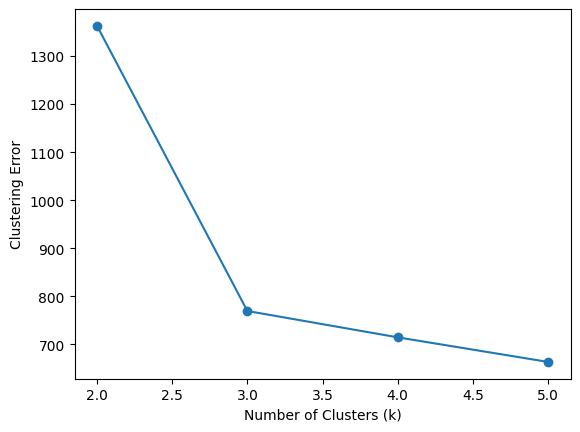

In [ ]:
plt.plot(k_values,errors,marker="o")

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Clustering Error")
plt.show()

In [ ]:
model = KMeans(n_clusters=3,random_state=42,n_init=10)

model.fit(X_scaled)

data["Cluster"] = model.labels_

In [ ]:
data[["Zone_Name","Cluster"]].head()

,Zone_Name,Cluster
0,Delivery Zone 001,2
1,Delivery Zone 002,2
2,Delivery Zone 003,1
3,Delivery Zone 004,1
4,Delivery Zone 005,1


In [ ]:
cluster_summary = data.groupby("Cluster")[X.columns].mean().round(1)

cluster_summary

,Average_Daily_Orders,Peak_Hour_Orders,Average_Order_Value_EGP,Average_Delivery_Distance_km,Average_Delivery_Time_min,Weekend_Order_Percentage,Cancellation_Rate_Percent,Restaurant_Count
Cluster,,,,,,,,
0,262.7,60.0,229.6,4.4,35.6,40.9,8.8,28.4
1,881.0,191.2,292.1,2.7,25.0,33.4,2.9,107.6
2,572.1,119.8,339.6,7.0,43.6,29.9,5.3,60.5


In [ ]:
cluster_names = {
    0: "Growth Opportunity Zones",
    1: "High-Demand Central Zones",
    2: "Wide-Coverage Zones"
}

data["Zone_Type"] = data["Cluster"].map(cluster_names)

In [ ]:
recommendations = {
    0: "Attract more restaurants and reduce cancellations",
    1: "Increase rider availability during peak hours",
    2: "Improve rider positioning for long-distance deliveries"
}

data["Recommended_Action"] = data["Cluster"].map(recommendations)

In [ ]:
data[["Zone_Name","Zone_Type","Recommended_Action"]].head(10)

,Zone_Name,Zone_Type,Recommended_Action
0,Delivery Zone 001,Wide-Coverage Zones,Improve rider positioning for long-distance de...
1,Delivery Zone 002,Wide-Coverage Zones,Improve rider positioning for long-distance de...
2,Delivery Zone 003,High-Demand Central Zones,Increase rider availability during peak hours
3,Delivery Zone 004,High-Demand Central Zones,Increase rider availability during peak hours
4,Delivery Zone 005,High-Demand Central Zones,Increase rider availability during peak hours
5,Delivery Zone 006,Growth Opportunity Zones,Attract more restaurants and reduce cancellations
6,Delivery Zone 007,Wide-Coverage Zones,Improve rider positioning for long-distance de...
7,Delivery Zone 008,Growth Opportunity Zones,Attract more restaurants and reduce cancellations
8,Delivery Zone 009,Wide-Coverage Zones,Improve rider positioning for long-distance de...
9,Delivery Zone 010,Growth Opportunity Zones,Attract more restaurants and reduce cancellations
